# Exercises for chapter 4: Skiplists

## Exercise 4.1. 

Illustrate the search paths for 2.5 and 5.5 on the skiplist in Figure 4.1.

![exercise_illustration 4.1](./ch04_resources/exs_4_1.png)


## Exercise 4.2. 

Illustrate the addition of the values 0.5 (with a height of 1) and then 3.5 (with a height of 2) to the skiplist in Figure 4.1.


![exercise_illustration 4.2](./ch04_resources/exs_4_2.png)

## Exercise 4.3. 

Illustrate the removal of the values 1 and then 3 from the skiplist in Figure 4.1.


![exercise_illustration 4.3](./ch04_resources/exs_4_3.png)

## Exercise 4.4. 

Illustrate the execution of remove(2) on the SkiplistList in Figure 4.5.


![exercise_illustration 4.3](./ch04_resources/exs_4_4.png)

## Exercise 4.5. 

Illustrate the execution of add(3, x) on the SkiplistList in Figure 4.5. Assume that pick height() selects a height of 4 for the newly created node.

![exercise_illustration 4.3](./ch04_resources/exs_4_5.png)

## Exercise 4.6. 
Show that, during an add(x) or a remove(x) operation, the expected number of pointers in a SkiplistSet that get changed is constant.

In [79]:
# =========
# add(x)
# =========
#
# According to lemma 4.2, the expected number of flips before we
# get a head is 2. which means, for every addition of n, The
# expected height is 1 (height 0 included).
#
# Therefore The 'stack' that assigns 'x' across Nodes and their
# pointers can also be expected to do the same number of operations
# No matter of actual height of previous Nodes or the current
# that is to be added.

# =========
# remove(x)
# =========
#
# Same logic for remove - even though remove does not use a stack,
# We can expect the same number of reassignments to be constant
# since the Node to be removed is of expected height of 1.



## Exercise 4.7. 

Suppose that, instead of promoting an element from Li−1
into Li based on a coin toss, we promote it with some probability p, 0 < p < 1.

lets define the probability of promotion as:

    p = 0.33

### 4.7.1. Show that, with this modification, the expected length of a search path is at most (1/p) log1/p n + O(1).


Let's first have a look at Lemma 4.1:
  - " The expected length of the search path for any node, u,
      in L0 is at most 2 log n + O(1) = O(log n). "

it is "2" log n, since we have to account for both vertical and
horisontal steps.

To count vertical steps look at Lemma 4.4, It is Log n, since
with coinflips, the chance of getting tails and continue to
flip is halved for each flip. That means that for each r L[r]
the number of nodes is halved, And we half until we reach the
bottom layer.

Since coinflips has an even probability of 0.5, the expected 
search Path becomes geometric, and the vertical direction is 
also log n. 

if we choose a different arbitrary probability in 0 < p < 1:,
lets say 0.33, this would no longer half the problem for each
level. The expression 

    (1/p) log1/p n + O(1) 

could then be written as:

    3.03 * log_{3,03} n + O(1).

So each height level has different costs in terms of number
of elements (n), which for example could make the number of 
vertical step fewer, but increase the number of horizontal steps. 

### 4.7.2. What is the value of p that minimizes the preceding expression?

In [80]:
from math import log2
import matplotlib.pyplot as plt
import numpy as np

def calculate_cost_of_p(p:float):
    x = 1/p
    return x / log2(x)

In [81]:
p_values = np.arange(0.001, 1.0, 0.001)
cost_values = [calculate_cost_of_p(p) for p in p_values]
p_cost_map = dict(zip(p_values, cost_values))
p_at_min_cost = min(p_cost_map, key=p_cost_map.get)

print(f"P at min: {p_at_min_cost}, Cost: {p_cost_map[p_at_min_cost]}")

P at min: 0.368, Cost: 1.8841694865285457


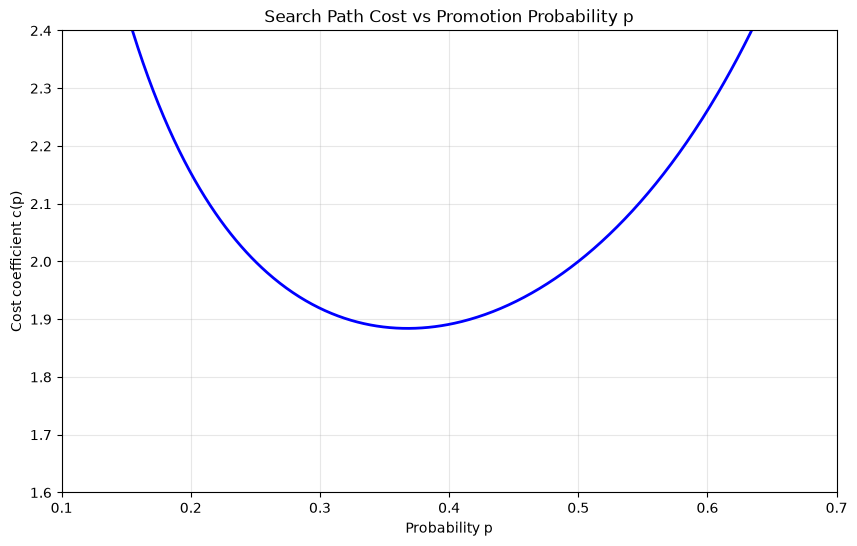

In [82]:
plt.figure(figsize=(10, 6))
plt.plot(p_values, cost_values, 'b-', linewidth=2)
plt.xlabel('Probability p')
plt.ylabel('Cost coefficient c(p)')
plt.title('Search Path Cost vs Promotion Probability p')
plt.xticks(np.arange(0.0, 1.0, 0.1))
plt.ylim(1.6, 2.4)
plt.xlim(0.1, 0.7)
plt.grid(True, alpha=0.3)
plt.show()

 ### 4.7.3. What is the expected height of the skiplist? 

In [83]:
def calculate_expected_height(p: float, n: int):
    """
    Calculate the expected height of a skiplist with promotion probability p.

    Formula (generalized Lemma 4.4):
        E[h] ≤ log n        + 2
    --> E[h] ≤ log_{1/p}(n) + 1/(1-p)

    """
    # Convert log_{1/p}(n) to base-2 for computation
    log_base_inv_p_n = log2(n) / log2(1/p)

    # constant term from the geometric series tail
    # (1 + 0.5 + 0.25 + ... = 2, when p: 0.5)
    constant_term = 1 / (1 - p)
    return log_base_inv_p_n + constant_term

#### p at standard 0.5

In [84]:
p = 0.50
n = 100

constant_term = 1 / 0.50
print(f"Constant term: {constant_term:.2f}")
print(f"log2(n): {log2(n):.2f}")
print(f"log2(1/p): {log2(p)}")

log_base_inv_p_n = log2(n) / log2(1/p)
print(f"log2(n) / log2(1/p) {log_base_inv_p_n:.2f}")
print(f"Expected height at p={p} and n={n}: {calculate_expected_height(p, n):.2f}")

Constant term: 2.00
log2(n): 6.64
log2(1/p): -1.0
log2(n) / log2(1/p) 6.64
Expected height at p=0.5 and n=100: 8.64


#### for our new hypothetical skiplist at p=0.33...

In [85]:
p = 0.33

constant_term = 1 / (1 - p)
print(f"Constant term: {constant_term:.2f}")
print(f"log2(1/p) {log2(p):.2f} --> that converts log2({n})")

log_base_inv_p_n = log2(n) / log2(1/p)
print(f"log2(n) / log2(1/p) {log_base_inv_p_n:.2f}")
print(f"Expected height at p={p} and n={n}: {calculate_expected_height(p, n):.2f}")

Constant term: 1.49
log2(1/p) -1.60 --> that converts log2(100)
log2(n) / log2(1/p) 4.15
Expected height at p=0.33 and n=100: 5.65


#### plot calculate_expected_height(p, n)

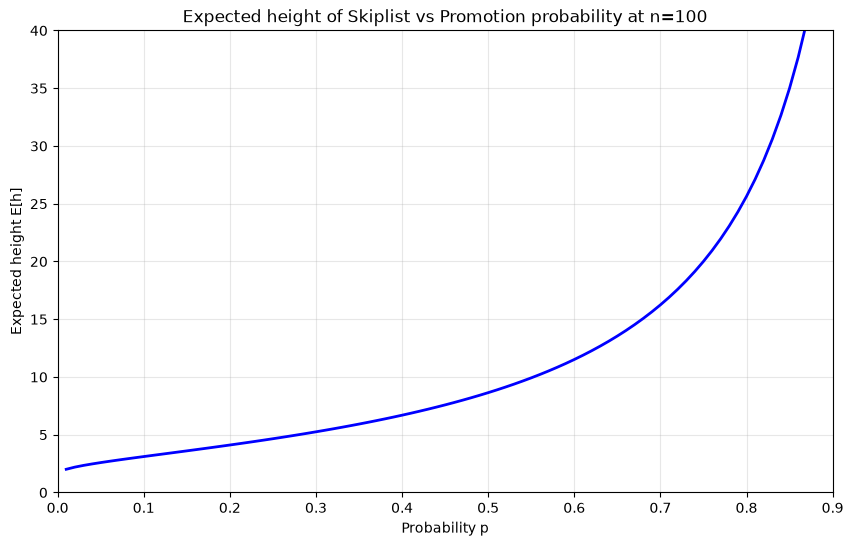

In [86]:
p_values = np.arange(0.01, 1.0, 0.01)
heights = [calculate_expected_height(p, n) for p in p_values]

plt.figure(figsize=(10, 6))
plt.plot(p_values, heights, 'b-', linewidth=2)
plt.xlabel("Probability p")
plt.ylabel("Expected height E[h]")
plt.title(f"Expected height of Skiplist vs Promotion probability at n={n}")
plt.xticks(np.arange(0.0, 1.0, 0.1))
plt.ylim(0, 40)
plt.xlim(0, 0.9)
plt.grid(True, alpha=0.3)
plt.show()

### 4.7.4. What is the expected number of nodes in the skiplist?

In [87]:
def calculate_expected_n_nodes(p:float, n:int):
    """
    Original proof in Lemma 4.3:
    ----------------------------
    "The probability that any particular element, x, is included in list
    Lr is 1/2r, so the expected number of nodes in Lr is n/2^r."

    generelized it becomes: E[n] = n/(1-p)
    This calculation does not include sentinel-nodes!

    """
    return n / (1-p)

#### sanity check: 200 nodes when p=0.5 and n=100

In [ ]:
p = 0.5
n = 100

print(f"Expected number of nodes at p={p} and n={n}: "
      f"{calculate_expected_n_nodes(p, n):.2f}")

Expected number of nodes at p=0.5 and n=100: 200.00


#### ~150 nodes at p=0.33 and n=100

In [93]:
p = 0.33
n = 100

print(f"Expected number of nodes at p={p} and n={n}: "
      f"{calculate_expected_n_nodes(p, n):.2f}")

Expected number of nodes at p=0.33 and n=100: 149.25


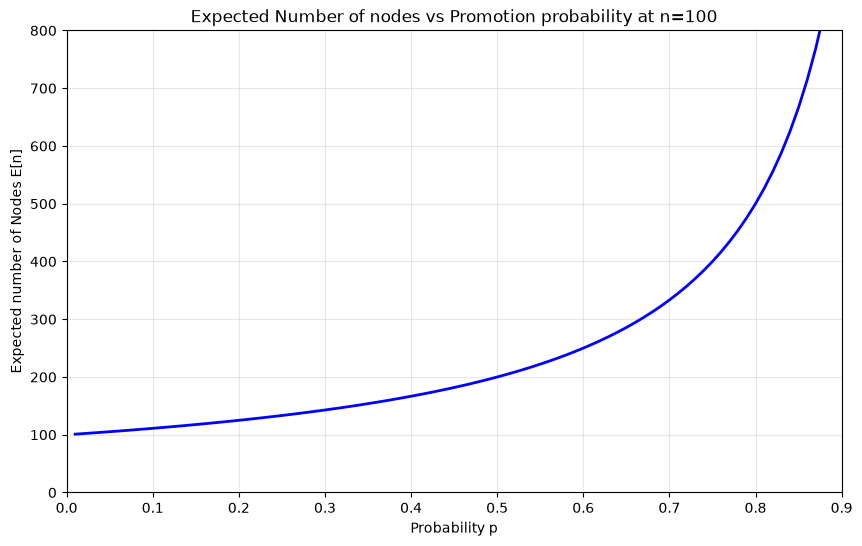

In [92]:
p_values = np.arange(0.01, 1.0, 0.01)
nodes = [calculate_expected_n_nodes(p, n) for p in p_values]

plt.figure(figsize=(10, 6))
plt.plot(p_values, nodes, 'b-', linewidth=2)
plt.xlabel("Probability p")
plt.ylabel("Expected number of Nodes E[n]")
plt.title(f"Expected Number of nodes vs Promotion probability at n={n}")
plt.xticks(np.arange(0.0, 1.0, 0.1))

plt.ylim(0, 800)
plt.xlim(0, 0.9)

plt.grid(True, alpha=0.3)
plt.show()

## Exercise 4.8. 

The find(x) method in a SkiplistSet sometimes performs redundant comparisons; these occur when x is compared to the same value more than once. They can occur when, for some node, u, u.next[r] = u.next[r−1]. Show how these redundant comparisons happen and modify find(x) so that they are avoided. Analyze the expected number of comparisons done by your modified find(x) method.

## Exercise 4.9. 

Design and implement a version of a skiplist that imple ments the SSet interface, but also allows fast access to elements by rank.

That is, it also supports the function get(i), which returns the element whose rank is i in O(log n) expected time. (The rank of an element x in an SSet is the number of elements in the SSet that are less than x.)

## Exercise 4.10. 

A finger in a skiplist is an array that stores the sequence of nodes on a search path at which the search path goes down. (The variable stack in the add(x) code on page 86 is a finger; the shaded nodes in Figure 4.3 show the contents of the finger.) One can think of a finger as pointing out the path to a node in the lowest list, L0 .

A finger search implements the find(x) operation using a finger, by walking up the list using the finger until reaching a node u such that u.x < x and u.next = nil or u.next.x > x and then performing a normal
search for x starting from u. It is possible to prove that the expected number of steps required for a finger search is O(1 + log r), where r is the
number values in L0 between x and the value pointed to by the finger.

Implement a subclass of Skiplist called SkiplistWithFinger that implements find(x) operations using an internal finger. This subclass stores a finger, which is then used so that every find(x) operation is implemented as a finger search. During each find(x) operation the finger is updated so
that each find(x) operation uses, as a starting point, a finger that points to the result of the previous find(x) operation.

## Exercise 4.11. 

Write a method, truncate(i), that truncates a SkiplistList at position i. After the execution of this method, the size of the list is i and it contains only the elements at indices 0, . . . , i − 1. The return value is another SkiplistList that contains the elements at indices i, . . . , n − 1. This
method should run in O(log n) time.



## Exercise 4.12. 

Write a SkiplistList method, absorb(l2), that takes as an argument a SkiplistList, l2 , empties it and appends its contents, in order, to the receiver. For example, if l1 contains a, b, c and l2 contains d, e, f, then after calling l1 .absorb(l2 ), l1 will contain a, b, c, d, e, f and l2 will be empty. This method should run in O(log n) time.

## Exercise 4.13. 

Using the ideas from the space-efficient list, SEList, design and implement a space-efficient SSet, SESSet. To do this, store the data, in order, in an SEList, and store the blocks of this SEList in an SSet. If the
original SSet implementation uses O(n) space to store n elements, then the SESSet will use enough space for n elements plus O(n/b + b) wasted space.

## Exercise 4.14. 

Using an SSet as your underlying structure, design and
implement an application that reads a (large) text file and allows you to search, interactively, for any substring contained in the text. As the user types their query, a matching part of the text (if any) should appear as a result.

- **Hint 1:** Every substring is a prefix of some suffix, so it suffices to store all suffixes of the text file.

- **Hint 2:** Any suffix can be represented compactly as a single integer indicating where the suffix begins in the text.

Test your application on some large texts, such as some of the books available at Project Gutenberg [1]. If done correctly, your applications will be very responsive; there should be no noticeable lag between typing keystrokes and seeing the results.

## Exercise 4.15. 

(This exercise should be done after reading about binary search trees, in Section 6.2.) Compare skiplists with binary search trees in the following ways:

1. Explain how removing some edges of a skiplist leads to a structure that looks like a binary tree and is similar to a binary search tree.

2. Skiplists and binary search trees each use about the same number of pointers (2 per node). Skiplists make better use of those pointers, though. Explain why.